# Taller reducido · 90 minutos
## Diseño de agentes basados en LLM

Esta libreta es el **recorrido lineal** del taller de hora y media: los cuatro
conceptos, en orden, sin desvíos. Si dispones de las tres horas completas, usa
las libretas 00 a 05; si tienes 90 minutos, ejecuta esta de arriba abajo.

**Antes de entrar en el aula** (esto no se hace en clase, se hace antes):

```bash
.venv/bin/python verificar_entorno.py
```

| Min | Bloque |
|---|---|
| 0–5 | Arranque: el mapa de los cuatro conceptos |
| 5–22 | **Rol** — `system_prompt` de un nodo |
| 22–45 | **Herramientas** — `ToolNode` y el bucle ReAct |
| 45–63 | **Memoria** — `checkpointer` y `Store` |
| 63–82 | **Planificación** — ReAct por dentro y el freno humano |
| 82–90 | Cierre: el mapa, el reto y la pregunta final |

**Lo que no cabe** y queda para casa: la auditoría de modelos en vivo, la
inspección del checkpoint, `plan-and-execute` completo, la persistencia en
SQLite, el *streaming* y el sistema multiagente. Todo está en las libretas
largas del taller de tres horas.

## El mapa: dónde vive cada concepto

| Concepto | En LangGraph | Cómo se ve |
|---|---|---|
| **Rol** | el `system_prompt` de un nodo | la función que escribes |
| **Herramientas** | `ToolNode` + una arista condicional | un nodo y una flecha |
| **Memoria** | `checkpointer` + `thread_id` · `Store` | el `config` que pasas en `invoke` |
| **Planificación** | las aristas del bucle | el grafo que dibujas |

La frase que sostiene todo: **en LangGraph la estructura del agente es un dato
que se puede imprimir, revisar y modificar.**

---

# 1. Rol

## 1.1 El grafo más pequeño posible

Tres piezas y ya hay un programa: un **estado** (el sobre que viaja entre nodos),
un **nodo** (función que devuelve *solo lo que cambia*) y unas **aristas**.

In [1]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.messages import SystemMessage
import comun

modelo = comun.llm()
print("Modelo del taller:", comun.elegir_modelo(verbose=False))

def crear_grafo(rol: str, checkpointer=None):
    """El mismo grafo, con el rol que le pasemos y memoria opcional."""
    def nodo(estado: MessagesState):
        return {"messages": [modelo.invoke([SystemMessage(content=rol)] + estado["messages"])]}

    c = StateGraph(MessagesState)
    c.add_node("agente", nodo)
    c.add_edge(START, "agente")
    c.add_edge("agente", END)
    return c.compile(checkpointer=checkpointer)


Modelo del taller: gemma4:31b-cloud


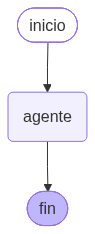

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	agente(agente)
	__end__([fin]):::last
	__start__ --> agente;
	agente --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 1: lo mínimo  ·  guardado en grafos/grafo-1-lo-minimo.mmd


In [2]:
comun.ver_grafo(crear_grafo("Eres un chef."), "Grafo 1: lo mínimo")


## 1.2 El rol es un parámetro, no una personalidad

La misma pregunta, dos roles, el mismo grafo. Si el rol cambia la respuesta,
es porque el rol es un dato del sistema, no una cadena escondida en una clase.

In [3]:
PREGUNTA = "Tengo pollo, arroz y espinacas. ¿Qué hago?"

for nombre, rol in {
    "CHEF": "Eres un chef mediterráneo. Propones platos sabrosos y rápidos.",
    "NUTRICIONISTA": "Eres un nutricionista deportivo. Das siempre cifras de calorías y macros.",
}.items():
    salida = crear_grafo(rol).invoke({"messages": [{"role": "user", "content": PREGUNTA}]})
    print("=" * 72)
    print(nombre)
    print("=" * 72)
    print(salida["messages"][-1].content[:340])
    print()


CHEF
¡Hola! Como chef mediterráneo, te diré que tienes los ingredientes perfectos para un plato equilibrado, saludable y lleno de sabor. No vamos a complicarnos; queremos comer rico y rápido.

Te propongo un **"Arroz Meloso de Pollo y Espinacas al Ajillo"**. Es una especie de risotto simplificado, muy jugoso.

Aquí tienes los pasos:

### ⏱️ Ti



NUTRICIONISTA
Como nutricionista deportivo, te recomiendo preparar un **Bowl de Pollo Energético con Arroz y Espinacas**. Esta es la combinación clásica de "combustible" para cualquier atleta: proteína de alta calidad para la recuperación muscular, carbohidratos complejos para el glucógeno y micronutrientes para la función celular.

Aquí tienes la prep



## 1.3 El rol da contenido, pero **no** garantiza la forma

Un rol orienta el tono. Lo que no hace es obligar a devolver una estructura.
En el taller largo lo medimos: pedir un JSON «por favor» falla una y otra vez.

La solución no es pedir mejor, es **cambiar de canal**: `response_format=` hace
que LangChain construya una *herramienta* cuyo esquema es tu modelo de Pydantic.
Es el mismo mecanismo que veremos ahora en el módulo de herramientas.

In [4]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent

class Receta(BaseModel):
    titulo: str = Field(description="Nombre del plato")
    minutos: int = Field(description="Tiempo total de preparación en minutos")
    ingredientes: list[str] = Field(description="Ingredientes necesarios")

agente = create_agent(
    modelo,
    tools=[],
    system_prompt="Eres un chef mediterráneo, conciso.",
    response_format=Receta,          # <- el contrato de formato
)

receta = agente.invoke(
    {"messages": [{"role": "user", "content": "Receta rápida con pollo."}]}
)["structured_response"]

print("tipo devuelto:", type(receta).__name__)
print("titulo      :", receta.titulo)
print("minutos     :", receta.minutos)
print("ingredientes:", receta.ingredientes)


tipo devuelto: Receta
titulo      : Pollo al Limón y Perejil
minutos     : 15
ingredientes: ['2 pechugas de pollo en dados', '2 dientes de ajo picados', '1 limón (zumo y ralladura)', 'Aceite de oliva virgen extra', 'Perejil fresco', 'Sal y pimienta']


---

# 2. Herramientas

El modelo **no ejecuta nada**: pide que se ejecute. Esa separación es todo el
módulo:

> El modelo **decide**. El grafo **ejecuta**. Tú **controlas qué puede decidir**.

## 2.1 Una herramienta es una función con docstring

El docstring no es documentación para humanos: **es el prompt de la
herramienta**. Es lo único que el modelo sabe de tu función.

In [5]:
import json
from langchain.tools import tool

@tool
def buscar_precio(producto: str) -> float:
    """Devuelve el precio estimado en EUR. Productos disponibles: pollo, arroz, espinacas."""
    return {"pollo": 5.0, "arroz": 2.0, "espinacas": 3.0}.get(producto.lower(), 9.99)

@tool
def convertir_moneda(cantidad: float, origen: str, destino: str) -> float:
    """Convierte una cantidad de dinero entre EUR y USD."""
    tasas = {("EUR", "USD"): 1.10, ("USD", "EUR"): 0.90}
    return round(cantidad * tasas.get((origen.upper(), destino.upper()), 1.0), 2)

HERRAMIENTAS = [buscar_precio, convertir_moneda]

print("Llamarlas yo mismo es Python normal:")
print("  buscar_precio ->", buscar_precio.invoke({"producto": "pollo"}))
print()
print("Y este es el contrato que recibe el modelo:")
print(json.dumps(buscar_precio.tool_call_schema.model_json_schema(), ensure_ascii=False, indent=2))


Llamarlas yo mismo es Python normal:
  buscar_precio -> 5.0

Y este es el contrato que recibe el modelo:
{
  "description": "Devuelve el precio estimado en EUR. Productos disponibles: pollo, arroz, espinacas.",
  "properties": {
    "producto": {
      "title": "Producto",
      "type": "string"
    }
  },
  "required": [
    "producto"
  ],
  "title": "buscar_precio",
  "type": "object"
}


## 2.2 El bucle ReAct es un grafo

```
START -> agente -> (¿pidió herramientas?) -> herramientas -> agente -> ... -> END
```

**El detalle que atasca:** `tools_condition` devuelve los literales `"tools"` y
`"__end__"`. Si tu nodo se llama `herramientas`, no lo adivina: hay que mapearlo.

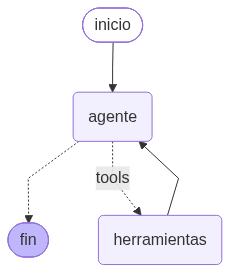

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	agente(agente)
	herramientas(herramientas)
	__end__([fin]):::last
	__start__ --> agente;
	agente -.-> __end__;
	agente -. tools .-> herramientas;
	herramientas --> agente;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 2: el bucle ReAct  ·  guardado en grafos/grafo-2-el-bucle-react.mmd


In [6]:
from langgraph.prebuilt import ToolNode, tools_condition

modelo_ct = modelo.bind_tools(HERRAMIENTAS)

def nodo_agente(estado: MessagesState):
    return {"messages": [modelo_ct.invoke(estado["messages"])]}

c = StateGraph(MessagesState)
c.add_node("agente", nodo_agente)
c.add_node("herramientas", ToolNode(HERRAMIENTAS))
c.add_edge(START, "agente")
c.add_conditional_edges("agente", tools_condition, {"tools": "herramientas", "__end__": END})
c.add_edge("herramientas", "agente")     # <- esta flecha es el bucle
react = c.compile()

comun.ver_grafo(react, "Grafo 2: el bucle ReAct")


## 2.3 La traza: la caja de cristal del agente

Lo importante no es que acierte, sino **ver cómo lo ha hecho**. Si en la traza no
aparece ningún `TOOL_CALLS`, el modelo **se lo está inventando**.

In [7]:
resultado = react.invoke(
    {"messages": [{"role": "user", "content": "¿Cuánto cuesta el pollo? ¿Y 100 EUR en USD?"}]}
)
comun.ver_mensajes(resultado)
print()
print("RESPUESTA FINAL:")
print(resultado["messages"][-1].content[:300])


[00] HumanMessage                 ¿Cuánto cuesta el pollo? ¿Y 100 EUR en USD?
[01] AIMessage  ->  TOOL_CALLS: buscar_precio({'producto': 'pollo'}), convertir_moneda({'cantidad': 100, 'destino': 'USD', 'origen': 'EUR'}) 
[02] ToolMessage                  5.0
[03] ToolMessage                  110.0
[04] AIMessage                    El pollo cuesta 5.0 EUR y 100 EUR equivalen a 110.0 USD.

RESPUESTA FINAL:
El pollo cuesta 5.0 EUR y 100 EUR equivalen a 110.0 USD.


## 2.4 Todo esto, en una línea

`create_agent` construye el mismo grafo que acabamos de montar a mano. Ahora ya
sabes qué hay dentro, que es lo que te permitirá depurarlo.

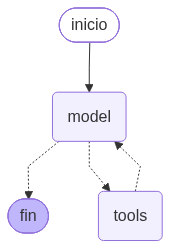

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	model(model)
	tools(tools)
	__end__([fin]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 2b: lo que construye create_agent por dentro  ·  guardado en grafos/grafo-2b-lo-que-construye-create-agent-por-dentro.mmd


In [8]:
agente_total = create_agent(
    modelo,
    tools=HERRAMIENTAS,
    system_prompt="Eres un chef conciso. Usa las herramientas para dar datos reales.",
)
comun.ver_grafo(agente_total, "Grafo 2b: lo que construye create_agent por dentro")


---

# 3. Memoria

Un LLM no recuerda: **le reenvías el historial**. Y hay dos memorias que se
confunden constantemente:

| | Corto plazo | Largo plazo |
|---|---|---|
| Qué guarda | la conversación | hechos del usuario |
| Dónde vive | `checkpointer` | `Store` |
| Se identifica por | `thread_id` | *namespace* |

## 3.1 Sin `checkpointer` hay amnesia; con él, hay hilo

Y el detalle cruel: **olvidar el `checkpointer` no da error**. Simplemente no hay
memoria. Es el fallo silencioso más caro del taller.

In [9]:
from langgraph.checkpoint.memory import InMemorySaver

sin_memoria = crear_grafo("Eres un chef conciso.")
con_memoria = crear_grafo("Eres un chef conciso.", InMemorySaver())
cfg_a = {"configurable": {"thread_id": "alumno-A"}}

sin_memoria.invoke({"messages": [{"role": "user", "content": "Me llamo Luis."}]})
r = sin_memoria.invoke({"messages": [{"role": "user", "content": "¿Cómo me llamo?"}]})
print("SIN memoria :", r["messages"][-1].content[:130])

con_memoria.invoke({"messages": [{"role": "user", "content": "Me llamo Luis."}]}, config=cfg_a)
r = con_memoria.invoke({"messages": [{"role": "user", "content": "¿Cómo me llamo?"}]}, config=cfg_a)
print("CON memoria :", r["messages"][-1].content[:130])

r = con_memoria.invoke({"messages": [{"role": "user", "content": "¿Cómo me llamo?"}]},
                       config={"configurable": {"thread_id": "alumno-B"}})
print("OTRO hilo  :", r["messages"][-1].content[:130])


SIN memoria : No lo sé. No estoy en tu libro de reservas.


CON memoria : Te llamas Luis.


OTRO hilo  : No lo sé. No estoy en tu libro de reservas.


## 3.2 El `Store`: memoria que cruza conversaciones

Lo que no pertenece a *esta* charla —una alergia, una preferencia— va al `Store`.
Y se consulta **desde una herramienta**, cuando hace falta: no ocupa contexto
hasta que se necesita.

La prueba: guardamos en el **hilo 1** y preguntamos en el **hilo 2**, que es una
conversación nueva. El `checkpointer` no puede ayudar ahí.

In [10]:
from langgraph.store.memory import InMemoryStore
from langchain.tools import ToolRuntime

ALUMNO = "luis"
almacen = InMemoryStore()

@tool
def guardar_preferencia(clave: str, valor: str, runtime: ToolRuntime) -> str:
    """Guarda un dato del alumno (alergia, preferencia) para futuras conversaciones."""
    item = runtime.store.get((ALUMNO,), "prefs")
    datos = dict(item.value) if item else {}
    datos[clave] = valor
    runtime.store.put((ALUMNO,), "prefs", datos)
    return f"guardado: {clave} = {valor}"

@tool
def leer_preferencias(runtime: ToolRuntime) -> str:
    """Devuelve los datos guardados del alumno."""
    item = runtime.store.get((ALUMNO,), "prefs")
    return str(item.value) if item else "no hay nada guardado"

chef = create_agent(
    modelo,
    tools=[guardar_preferencia, leer_preferencias],
    store=almacen,
    system_prompt=("Eres un chef conciso. Guarda los datos personales que te cuenten "
                   "y consúltalos antes de proponer un plato."),
)

chef.invoke({"messages": [{"role": "user", "content": "Soy alérgico a los frutos secos. Apúntalo."}]},
            config={"configurable": {"thread_id": "hilo-1"}})

respuesta = chef.invoke({"messages": [{"role": "user", "content": "¿Qué alergias tengo? Propón una cena."}]},
                        config={"configurable": {"thread_id": "hilo-2"}})

print("HILO 2 (conversación nueva):")
print(respuesta["messages"][-1].content[:300])
print()
comun.ver_mensajes(respuesta)


HILO 2 (conversación nueva):
Tienes alergia a los **frutos secos**.

**Propuesta de cena:** Salmón al horno con espárragos trigueros y patatas baby. Simple, saludable y seguro.

[00] HumanMessage                 ¿Qué alergias tengo? Propón una cena.
[01] AIMessage  ->  TOOL_CALLS: leer_preferencias({}) 
[02] ToolMessage                  {'alergia': 'frutos secos'}
[03] AIMessage                    Tienes alergia a los **frutos secos**.  **Propuesta de cena:** Salmón al horno con espárragos trigueros y patatas baby. Simple, saludable y seguro.


---

# 4. Planificación

ReAct decide **un paso cada vez**, mirando solo lo que ya ha pasado. Es
reactivo. Veámoslo por dentro y pongámosle un freno humano.

## 4.1 Cuántas vueltas da el bucle

Le pedimos algo que obliga a encadenar: primero el precio, y solo después la
conversión. El agente no sabe al empezar cuántas llamadas hará.

In [11]:
tarea = "¿Cuánto cuestan 3 kg de pollo en USD? Necesito primero el precio en EUR."
salida = react.invoke({"messages": [{"role": "user", "content": tarea}]})

vueltas = sum(1 for m in salida["messages"] if getattr(m, "tool_calls", None))
print("TAREA:", tarea)
print()
comun.ver_mensajes(salida)
print()
print(f"Vueltas del bucle ReAct: {vueltas}  (cada vuelta es una llamada al modelo)")


TAREA: ¿Cuánto cuestan 3 kg de pollo en USD? Necesito primero el precio en EUR.

[00] HumanMessage                 ¿Cuánto cuestan 3 kg de pollo en USD? Necesito primero el precio en EUR.
[01] AIMessage  ->  TOOL_CALLS: buscar_precio({'producto': 'pollo'}) 
[02] ToolMessage                  5.0
[03] AIMessage  ->  TOOL_CALLS: convertir_moneda({'cantidad': 15, 'destino': 'USD', 'origen': 'EUR'}) 
[04] ToolMessage                  16.5
[05] AIMessage                    El precio de 1 kg de pollo es de 5 EUR, por lo que 3 kg cuestan **15 EUR**.   Al convertirlo, el precio total es de **16.50 USD**.

Vueltas del bucle ReAct: 2  (cada vuelta es una llamada al modelo)


## 4.2 El freno humano: `interrupt()`

Un agente que puede gastar dinero necesita poder pararse. `interrupt()` **pausa**
el grafo y `Command(resume=...)` lo reanuda en el mismo punto. Requiere
`checkpointer`: es lo que permite guardar el estado mientras está parado.

In [12]:
from langgraph.types import interrupt, Command
from langchain_core.messages import AIMessage

def nodo_compra(estado: MessagesState):
    propuesta = modelo.invoke([
        SystemMessage(content="Eres un chef conciso."),
        ("human", "Propón una lista de la compra breve para 4 personas."),
    ]).content

    # El grafo se detiene AQUÍ y espera una decisión humana.
    decision = interrupt({"propuesta": propuesta, "pregunta": "¿Aprobamos este gasto?"})
    return {"messages": [AIMessage(content=f"DECISIÓN HUMANA: {decision}")]}

g = StateGraph(MessagesState)
g.add_node("compra", nodo_compra)
g.add_edge(START, "compra")
g.add_edge("compra", END)
hitl = g.compile(checkpointer=InMemorySaver())

cfg_compra = {"configurable": {"thread_id": "compra-1"}}
parada = hitl.invoke({"messages": [{"role": "user", "content": "Prepara la compra."}]},
                     config=cfg_compra)

aviso = parada["__interrupt__"][0].value
print("El grafo está EN PAUSA.")
print("  Pregunta :", aviso["pregunta"])
print("  Propuesta:", aviso["propuesta"][:200].replace("\n", " "))


El grafo está EN PAUSA.
  Pregunta : ¿Aprobamos este gasto?
  Propuesta: Para un menú equilibrado de 3 días (Pollo con verduras, Pasta boloñesa y Salmón con arroz):  **Proteínas:** * 800g pechuga de pollo. * 500g carne picada mixta. * 4 lomos de salmón. * 1 docena de huevo


In [13]:
print("El humano responde y el grafo continúa exactamente donde se quedó:\n")
final = hitl.invoke(Command(resume="Aprobado, pero sin cilantro."), config=cfg_compra)
print(final["messages"][-1].content[:250])


El humano responde y el grafo continúa exactamente donde se quedó:



DECISIÓN HUMANA: Aprobado, pero sin cilantro.


---

# Cierre

## El mapa completo

| Concepto | Dónde vive | Lo has visto en |
|---|---|---|
| **Rol** | `system_prompt` de un nodo | 1.1 – 1.3 |
| **Herramientas** | `ToolNode` + arista condicional | 2.1 – 2.4 |
| **Memoria** | `checkpointer` + `Store` | 3.1 – 3.2 |
| **Planificación** | las aristas del bucle + `interrupt` | 4.1 – 4.2 |

`create_agent` empaqueta los tres primeros en una línea. La planificación es lo
que **tú** añades encima, porque depende de tu problema: no hay una estrategia
que gane siempre.

## Para casa

1. **`plan-and-execute`**: un campo `plan` y un contador en el estado. Está
   completo en la libreta `04_planificacion.ipynb` del taller largo.
2. **Persistencia real**: cambiar `InMemorySaver` por `SqliteSaver` para que la
   memoria sobreviva al reinicio.
3. **Multiagente**: un supervisor que reparte entre especialistas
   (`05_ampliaciones.ipynb`).
4. **`streaming`**: responder mientras el modelo escribe.

## La pregunta que importa

> **¿En qué punto exacto de tu grafo tomaría una decisión equivocada el agente,
> y cómo te enterarías?**

Si sabes responder eso, has entendido el taller. Si no, has aprendido a invocar
una API.